## Placeholder

text

In [1]:
from rowland_geometry import Analyzer, DispersiveSpectrometer, ReferenceFrame

sbca = Analyzer(
    material = 'Si',
    reflection = [5,5,1],
    cut = [2,1,1],
    bending_radius=300,
    optic_diameter=100
)

display(sbca.as_dict())


{'material': 'Silicon',
 'reflection': [5, 5, 1],
 'cut': [2, 1, 1],
 'bending_radius': 300.0,
 'optic_diameter': 100.0,
 'd_hkl': 0.7604838519831163,
 'e0': 8151.664895755907,
 'crystal_asymmetry': 23.842636023792352,
 'miscut': 0.0,
 'asymmetry': 23.842636023792352}

In [28]:
delta = 0

drr_spec = DispersiveSpectrometer(
    analyzer = sbca,
    displacement = delta,
    bragg = 90-23.8,
    asymmetry_direction=-1
)

bin_wd = None


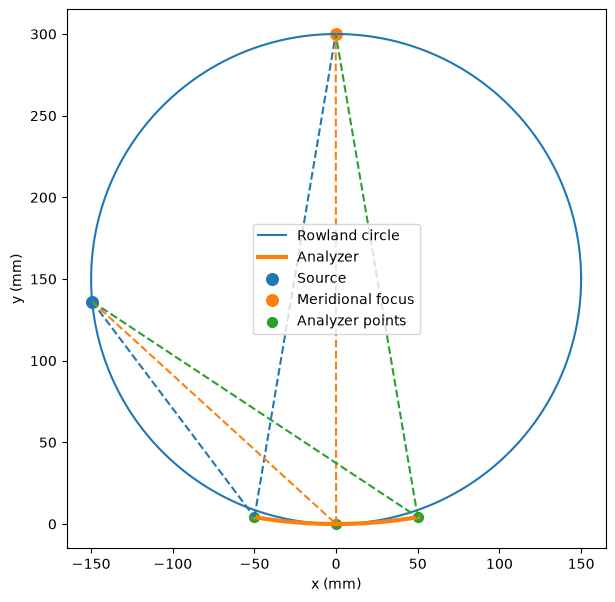

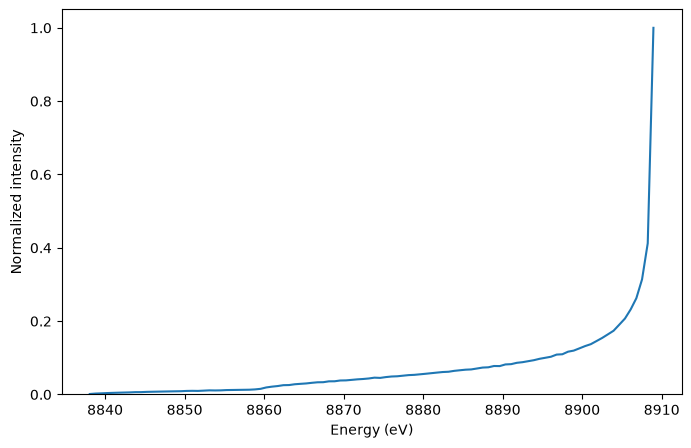

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Example dispersive spectrometer
# ------------------------------------------------------------

spec = drr_spec

# ------------------------------------------------------------
# Geometry pieces from the spectrometer
# ------------------------------------------------------------

geometry = spec.geometry
circle = geometry.on_circle_geometry

source = geometry.pos_source
focus_m = geometry.pos_meridional
profile = geometry.profile_analyzer_pos

left = profile[0]
center = profile[len(profile) // 2]
right = profile[-1]

analyzer_points = [left, center, right]
ray_colors = ["C0", "C1", "C2"]

# Rowland circle
theta = np.linspace(0, 2 * np.pi, 1000)

R_circle = geometry.diameter / 2.0
xc = 0.0
yc = R_circle

x_circle = xc + R_circle * np.cos(theta)
y_circle = yc + R_circle * np.sin(theta)

# ------------------------------------------------------------
# Plot 1: geometry + incident/outgoing rays
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(
    x_circle,
    y_circle,
    label="Rowland circle",
)

ax.plot(
    profile[:, 0],
    profile[:, 1],
    linewidth=3,
    label="Analyzer",
)

ax.scatter(
    source[0],
    source[1],
    s=70,
    label="Source",
)

ax.scatter(
    focus_m[0],
    focus_m[1],
    s=70,
    label="Meridional focus",
)

ax.scatter(
    [left[0], center[0], right[0]],
    [left[1], center[1], right[1]],
    s=50,
    label="Analyzer points",
)

# Incident and outgoing ray pairs
for point, color in zip(analyzer_points, ray_colors):

    # Incident ray: source -> analyzer
    ax.plot(
        [source[0], point[0]],
        [source[1], point[1]],
        linestyle="--",
        color=color,
    )

    # Outgoing ray: analyzer -> meridional focus
    ax.plot(
        [point[0], focus_m[0]],
        [point[1], focus_m[1]],
        linestyle="--",
        color=color,
    )

ax.set_aspect("equal")
ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")
ax.legend()

plt.show()


# ------------------------------------------------------------
# Energy response
# ------------------------------------------------------------

energy_axis, response = spec.energy_response(
    bin_width=bin_wd
)

# ------------------------------------------------------------
# Plot 2: peak-normalized geometric energy response
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    energy_axis,
    response,
)

ax.set_xlabel("Energy (eV)")
ax.set_ylabel("Normalized intensity")
ax.set_ylim(0, 1.05)

plt.show()